# Hugoniot Fits: Coesite


In [1]:
%%capture 
## This cell loads the modules, data, and EOS parameters
## capture magic function hides the output; comment out to see diagnostic info during data load
## Run executable notebook for output

%run -i scripts/set_paths
%run -i scripts/load_modules
%run -i scripts/load_silica_data
%run -i scripts/define_mc
%run -i scripts/define_eos
%run -i scripts/calibrate_decaying_shocks.py
%run -i scripts/load_vapor_domes.py
%run -i scripts/load_liquid_model.py
%run -i scripts/load_solid_models.py
#%run -i scripts/hugoniot-entropy.py # not needed here
%run -i scripts/intersection.py # intersection function
#%run -i scripts/odr_models.py # ODR and model functions - not needed here
%run -i scripts/set_plotstyle.py # customize matplotlib
%run -i scripts/set_colors.py # custom colors

# this notebook's figure name tag
tag = 'CST-'


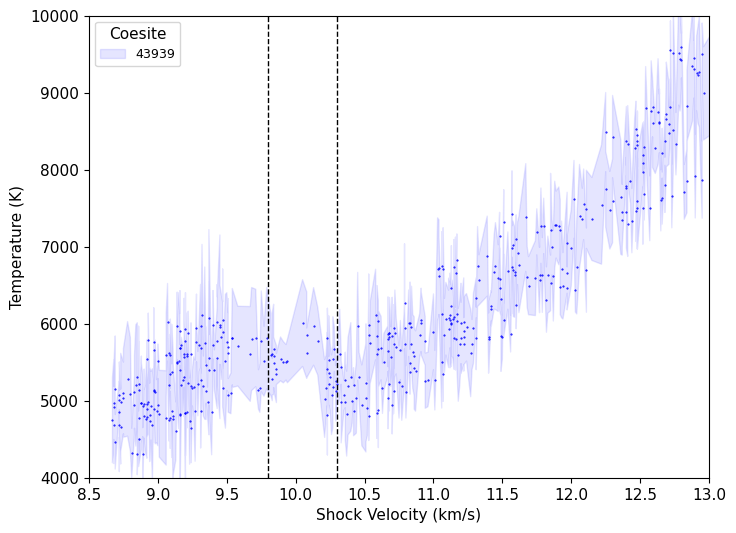

4.11706989938652 4.472334594142762


In [2]:
fig, ax = plt.subplots(figsize=fsize)
ax.set_prop_cycle(custom_cycler)

#plt.title('Coesite Temperature Inversion')
plt.plot(shockdat_list[F24cst43939['id']].us,shockdat_list[F24cst43939['id']].T,'.',color='b',markersize=1)
plt.fill_between(shockdat_list[F24cst43939['id']].us,shockdat_list[F24cst43939['id']].T-shockdat_list[F24cst43939['id']].T_std,shockdat_list[F24cst43939['id']].T+shockdat_list[F24cst43939['id']].T_std, color='blue', alpha = 0.1,label='43939')

plt.plot([cst_wiggle_us1,cst_wiggle_us1],[4000,12000],'k--')
plt.plot([cst_wiggle_us2,cst_wiggle_us2],[4000,12000],'k--')

plt.xlim(8.5,13)
plt.ylim(4000,10000)
plt.legend(title='Coesite',fontsize=lfss)
plt.xlabel('Shock Velocity (km/s)')
plt.ylabel('Temperature (K)')
plt.show()
cst_wiggle_up1 = np.interp(cst_wiggle_us1,cst_hug_liq.us,cst_hug_liq.up)
cst_wiggle_up2 = np.interp(cst_wiggle_us2,cst_hug_liq.us,cst_hug_liq.up)
cst_wiggle_P1 = np.interp(cst_wiggle_us1,cst_hug_liq.us,cst_hug_liq.P)
cst_wiggle_P2 = np.interp(cst_wiggle_us2,cst_hug_liq.us,cst_hug_liq.P)

print(cst_wiggle_up1,cst_wiggle_up2)

## Us-up fits


[0.66 1.11 1.48 2.04 2.86 3.48 4.05]
FIT EOS a =  [2.59532144 1.68055338]
FIT EOS cov =  [[ 0.15506464 -0.0452009 ]
 [-0.0452009   0.01334589]]
Saved EOS fit in cst_fit_cacl2_linear.txt
Saved EOS fit in readable file cst_fit_cacl2_linear-readable.txt
rms =  0.06196020877346302
cst_fit_cacl2 check:
Coefficients are the same.
[2.59532144 1.68055338]
[2.59532144 1.68055338]
FIT EOS a =  [4.00563039 1.40740132]
FIT EOS cov =  [[ 0.32098594 -0.03182132]
 [-0.03182132  0.00338922]]
Saved EOS fit in cst_fit_liq_linear.txt
Saved EOS fit in readable file cst_fit_liq_linear-readable.txt
rms =  0.24594546590549066
cst_fit_liq check:
Coefficients are the same.
[4.00563039 1.40740132]
[4.00563039 1.40740132]


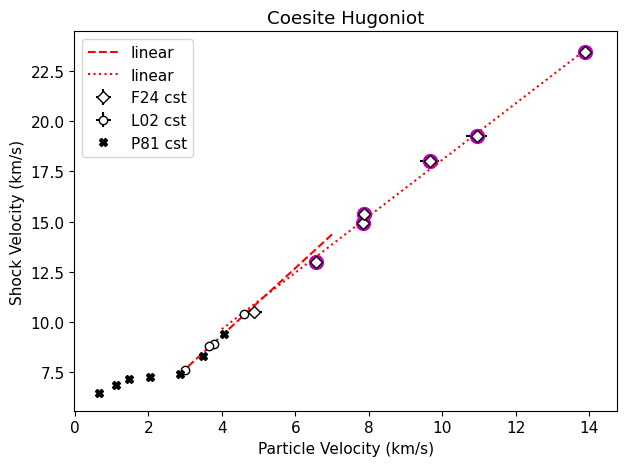

In [3]:
print(shockdat_list[P81cst['id']].up)
plt.errorbar(shockdat_list[F24cst['id']].up,shockdat_list[F24cst['id']].us,fmt='kD',mfc='white',label=F24cst['lab'],\
            xerr=shockdat_list[F24cst['id']].up_std,yerr=shockdat_list[F24cst['id']].us_std)
plt.errorbar(shockdat_list[L02cst['id']].up,shockdat_list[L02cst['id']].us,fmt='ko',mfc='white',label=L02cst['lab'],\
            xerr=shockdat_list[L02cst['id']].up_std,yerr=shockdat_list[L02cst['id']].us_std)
plt.errorbar(shockdat_list[P81cst['id']].up,shockdat_list[P81cst['id']].us,fmt='kX',label=P81cst['lab'],)

cst_P_all1 = [shockdat_list[P81cst['id']].P,shockdat_list[L02cst['id']].P,shockdat_list[F24cst['id']].P]
cst_P_all = np.concatenate([np.atleast_1d(x) for x in cst_P_all1])

cst_up_all1 = [shockdat_list[P81cst['id']].up,shockdat_list[L02cst['id']].up,shockdat_list[F24cst['id']].up]
cst_up_all = np.concatenate([np.atleast_1d(x) for x in cst_up_all1])
cst_up_std_all1 = [shockdat_list[P81cst['id']].up*.02,shockdat_list[L02cst['id']].up_std,shockdat_list[F24cst['id']].up_std]
cst_up_std_all = np.concatenate([np.atleast_1d(x) for x in cst_up_std_all1])

# assume 2% errors in Podurets 1981 velocities
cst_us_all1 = [shockdat_list[P81cst['id']].us,shockdat_list[L02cst['id']].us,shockdat_list[F24cst['id']].us]
cst_us_all = np.concatenate([np.atleast_1d(x) for x in cst_us_all1])
cst_us_std_all1 = [shockdat_list[P81cst['id']].us*.02,shockdat_list[L02cst['id']].us_std,shockdat_list[F24cst['id']].us_std]
cst_us_std_all = np.concatenate([np.atleast_1d(x) for x in cst_us_std_all1])

r1 = np.full(len(shockdat_list[P81cst['id']].up), shockdat_list[P81cst['id']].refidlist[1], dtype=int)
r2 = np.full(len(shockdat_list[L02cst['id']].up), shockdat_list[L02cst['id']].refidlist[1], dtype=int)
r3 = np.full(len(shockdat_list[F24cst['id']].up), shockdat_list[F24cst['id']].refidlist[1], dtype=int)

cst_refid_all1 = np.concatenate((r1,r2,r3))
cst_refid_all = np.concatenate([np.atleast_1d(x) for x in cst_refid_all1])



if 0:
    ind = np.where(shockdat_list[F24cst['id']].P>200)
    fitupcst1 = [shockdat_list[F24cst['id']].up[ind]]
    fitupcst = np.concatenate([np.atleast_1d(x) for x in fitupcst1])
    
    fituperrcst1 = [shockdat_list[F24cst['id']].up_std[ind]]
    fituperrcst = np.concatenate([np.atleast_1d(x) for x in fituperrcst1])
    
    fituscst1 = [shockdat_list[F24cst['id']].us[ind]]
    fituscst = np.concatenate([np.atleast_1d(x) for x in fituscst1])
    
    fituserrcst1 = [shockdat_list[F24cst['id']].us_std[ind]]
    fituserrcst = np.concatenate([np.atleast_1d(x) for x in fituserrcst1])
    
    print(fituperrcst/fitupcst)
    print(fituserrcst/fituscst)

if 1:
    ind = np.where((cst_up_all > 2.5) & (cst_up_all < 4.25))
    fitx = cst_up_all[ind]
    fitf= cst_us_all[ind]
    fitx_std = cst_up_std_all[ind]
    fitf_std = cst_us_std_all[ind]
    fitrefid = cst_refid_all[ind]
    fitreflist=[]
    for i in np.unique(fitrefid):
        fitreflist.append(str(i)+': '+ref_list[i].reference[0])
    
    
    # initialize the HPeos_Fit class
    cst_fit_cacl2 = hp.HPeos_Fit()
    cst_fit_cacl2.matid = 149
    cst_fit_cacl2.material = 'Coesite'
    cst_fit_cacl2.formula = 'SiO2'
    cst_fit_cacl2.rho_ref = 2.92
    cst_fit_cacl2.rho_ref_std = 0.03
    cst_fit_cacl2.rho_ref_units = 'g/cm³'
    cst_fit_cacl2.x = fitx
    cst_fit_cacl2.f = fitf
    cst_fit_cacl2.x_std = fitx_std
    cst_fit_cacl2.f_std = fitf_std
    cst_fit_cacl2.refid = fitrefid
    cst_fit_cacl2.reflist = fitreflist
    cst_fit_cacl2.x_var = 'up'
    cst_fit_cacl2.f_var = 'us'
    cst_fit_cacl2.x_units = 'km/s'
    cst_fit_cacl2.f_units = 'km/s'
    cst_fit_cacl2.x_desc = 'Particle Velocity'
    cst_fit_cacl2.f_desc = 'Shock Velocity'
    cst_fit_cacl2.phase_fit = 'CaCl2'
    cst_fit_cacl2.remlist.append('Fit to solid region on the Hugoniot.')
    DateTime_in_ISOFormat = datetime.datetime.now(zoneinfo.ZoneInfo('UTC')).isoformat('T', 'seconds') #
    cst_fit_cacl2.actions = [['Sarah T. Stewart','create',DateTime_in_ISOFormat,'new fit']]

    cst_fit_cacl2.curvetype = 'linear'
    cst_fit_cacl2.outputfitpath = outputfitpath # in load_paths.py
    cst_fit_cacl2.filename = 'cst_fit_cacl2_linear'
    cst_fit_cacl2.fit()
    print('FIT EOS a = ',cst_fit_cacl2.a)
    print('FIT EOS cov = ',cst_fit_cacl2.cov)
    cst_fit_cacl2.savejson()
    cst_fit_cacl2.savereadable()
    print('rms = ',cst_fit_cacl2.rms)

    print('cst_fit_cacl2 check:')
    cst_fit_cacl2.comparecoefs(cst_fit_cacl20.a)

    nup = np.arange(min(fitx),7,.01)
    nus = cst_fit_cacl2.calcf(nup)
    plt.plot(nup,nus,'r--',label='linear')

if 1:
    ind = np.where(cst_P_all>200)
    fitx = cst_up_all[ind]
    fitf= cst_us_all[ind]
    fitx_std = cst_up_std_all[ind]
    fitf_std = cst_us_std_all[ind]
    fitrefid = cst_refid_all[ind]
    fitreflist=[]
    for i in np.unique(fitrefid):
        fitreflist.append(str(i)+': '+ref_list[i].reference[0])
    
    
    # initialize the HPeos_Fit class
    cst_fit_liq = hp.HPeos_Fit()
    cst_fit_liq.matid = 149
    cst_fit_liq.material = 'Coesite'
    cst_fit_liq.formula = 'SiO2'
    cst_fit_liq.rho_ref = 2.92
    cst_fit_liq.rho_ref_std = 0.03
    cst_fit_liq.rho_ref_units = 'g/cm³'
    cst_fit_liq.x = fitx
    cst_fit_liq.f = fitf
    cst_fit_liq.x_std = fitx_std
    cst_fit_liq.f_std = fitf_std
    cst_fit_liq.refid = fitrefid
    cst_fit_liq.reflist = fitreflist
    cst_fit_liq.x_var = 'up'
    cst_fit_liq.f_var = 'us'
    cst_fit_liq.x_units = 'km/s'
    cst_fit_liq.f_units = 'km/s'
    cst_fit_liq.x_desc = 'Particle Velocity'
    cst_fit_liq.f_desc = 'Shock Velocity'
    cst_fit_liq.phase_fit = 'liquid'
    cst_fit_liq.remlist.append('Fit to liquid region on the Hugoniot.')
    DateTime_in_ISOFormat = datetime.datetime.now(zoneinfo.ZoneInfo('UTC')).isoformat('T', 'seconds') #
    cst_fit_liq.actions = [['Sarah T. Stewart','create',DateTime_in_ISOFormat,'new fit']]

    cst_fit_liq.curvetype = 'linear'
    cst_fit_liq.outputfitpath = outputfitpath # in load_paths.py
    cst_fit_liq.filename = 'cst_fit_liq_linear'
    cst_fit_liq.fit()
    print('FIT EOS a = ',cst_fit_liq.a)
    print('FIT EOS cov = ',cst_fit_liq.cov)
    cst_fit_liq.savejson()
    cst_fit_liq.savereadable()
    print('rms = ',cst_fit_liq.rms)

    print('cst_fit_liq check:')
    cst_fit_liq.comparecoefs(cst_fit_liq0.a)

    plt.plot(fitx,fitf,'mo',markersize=10)
    nup = np.arange(4,max(fitx),.01)
    nus = cst_fit_liq.calcf(nup)
    plt.plot(nup,nus,'r:',label='linear')



plt.xlabel('Particle Velocity (km/s)')
plt.ylabel('Shock Velocity (km/s)')
plt.title('Coesite Hugoniot')
#plt.xlim(2,12)
#plt.ylim(5,20)
plt.legend()


#plt.plot([2.5,2.5],[5,20])
#plt.plot([4.25,4.25],[5,20])
figname='cst-us-up'
plt.tight_layout()
plt.savefig(outputfigpath+figname+'.pdf')
plt.show()


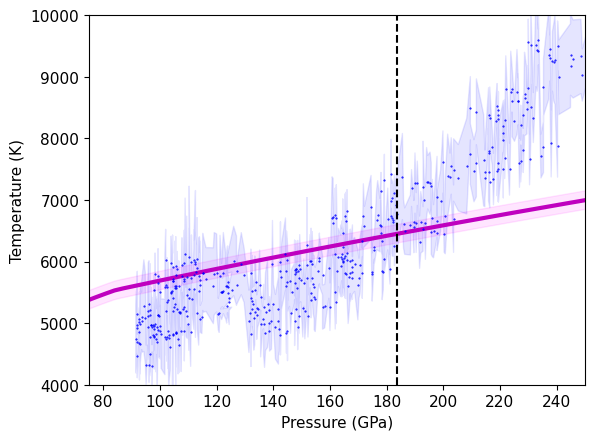

In [4]:
ind = np.where(stsmcsmooth.P <=550)[0]
plt.plot(stsmcsmooth.P[ind],stsmcsmooth.T[ind],'m-',linewidth=3,label='Proposed melt curve')
plt.fill_between(stsmcsmooth.P,stsmcsmooth.T-150,stsmcsmooth.T+150,color='magenta',alpha=0.1)
ind = np.where(stsmcsmooth.P >=550)[0]
plt.plot(stsmcsmooth.P[ind],stsmcsmooth.T[ind],'m:',linewidth=3)
# Plot Andrault et al. 2022 triple points
#plt.plot([Pt1, 40, Pt2],[Tt1,4800,Tt2],'mD')
#plt.plot([Pt3],[Tt3],'mD')#,mfc='white') # estimate from extrapolated T04 GGA boundary; same value 
#plt.plot(C84939[:,0],C84939[:,9],'.')
#plt.plot(C84941[:,1],C84941[:,9],'.')
#plt.plot(C84943[:,0],C84943[:,9],'.')
#plt.plot(C43939.P,C43939.T,'.')
#plt.plot(C43941.P,C43941.T,'.')
#plt.plot(C43943.P,C43943.T,'.')


plt.plot(C43939.P,C43939.T,'.',color='b',markersize=1)
plt.fill_between(C43939.P,C43939.T-C43939.T_std,C43939.T+C43939.T_std, color='blue', alpha = 0.1)
#plt.plot(C43941.P,C43941.T,'.',color='orange',markersize=1)
#plt.fill_between(C43941.P,C43941.T-C43941.T_std,C43941.T+C43941.T_std, color='orange', alpha = 0.1)
#plt.plot(C43943.P,C43943.T,'.',color='green',markersize=1)
#plt.fill_between(C43943.P,C43943.T-C43943.T_std,C43943.T+C43943.T_std, color='green', alpha = 0.1)


plt.xlim(75,250)
plt.ylim(4000,10000)
plt.plot([cst_liquidus_P,cst_liquidus_P],[4000,12000],'k--')
#dong_dat = np.loadtxt('../data_silica_db/dong-mc.csv',skiprows=0,delimiter=',')
#plt.plot(dong_dat[:,0],dong_dat[:,1],'--',color='red',label='Dong et al. MC')

plt.xlabel('Pressure (GPa)')
plt.ylabel('Temperature (K)')
plt.show()

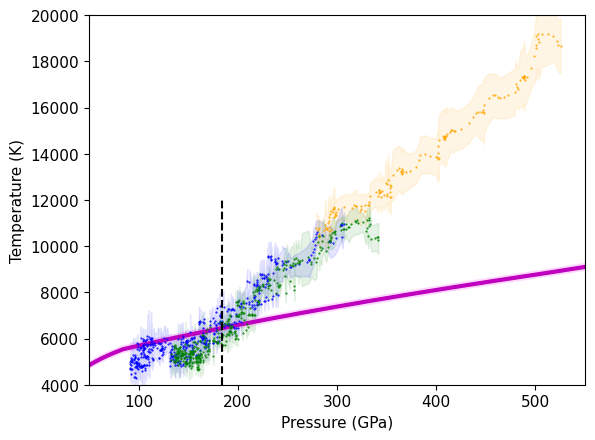

In [5]:
ind = np.where(stsmcsmooth.P <=550)[0]
plt.plot(stsmcsmooth.P[ind],stsmcsmooth.T[ind],'m-',linewidth=3,label='Proposed melt curve')
plt.fill_between(stsmcsmooth.P,stsmcsmooth.T-150,stsmcsmooth.T+150,color='magenta',alpha=0.1)
ind = np.where(stsmcsmooth.P >=550)[0]
plt.plot(stsmcsmooth.P[ind],stsmcsmooth.T[ind],'m:',linewidth=3)

plt.plot(C43939.P,C43939.T,'.',color='b',markersize=1)
plt.fill_between(C43939.P,C43939.T-C43939.T_std,C43939.T+C43939.T_std, color='blue', alpha = 0.1)
plt.plot(C43941.P,C43941.T,'.',color='orange',markersize=1)
plt.fill_between(C43941.P,C43941.T-C43941.T_std,C43941.T+C43941.T_std, color='orange', alpha = 0.1)
plt.plot(C43943.P,C43943.T,'.',color='green',markersize=1)
plt.fill_between(C43943.P,C43943.T-C43943.T_std,C43943.T+C43943.T_std, color='green', alpha = 0.1)


plt.xlim(50,550)
plt.ylim(4000,20000)
plt.plot([cst_liquidus_P,cst_liquidus_P],[4000,12000],'k--')
#dong_dat = np.loadtxt('../data_silica_db/dong-mc.csv',skiprows=0,delimiter=',')
#plt.plot(dong_dat[:,0],dong_dat[:,1],'--',color='red',label='Dong et al. MC')

plt.xlabel('Pressure (GPa)')
plt.ylabel('Temperature (K)')
plt.show()

HPEOS T-Us FIT LIQUID REGION
FIT EOS a =  [-1474.22116721  -116.72424841    68.71354409]
FIT EOS cov =  [[ 1.03177041e+06 -1.63159569e+05  6.33179124e+03]
 [-1.63159569e+05  2.59177416e+04 -1.01083446e+03]
 [ 6.33179124e+03 -1.01083446e+03  3.96533619e+01]]
Saved EOS fit in cst_fitTus_liq_quadratic.txt
Saved EOS fit in readable file cst_fitTus_liq_quadratic-readable.txt
rms =  493.51736651674764
cst_fitTus_liq check:
Coefficients are the same.
[-1474.22116721  -116.72424841    68.71354409]
[-1474.22116721  -116.72424841    68.71354409]


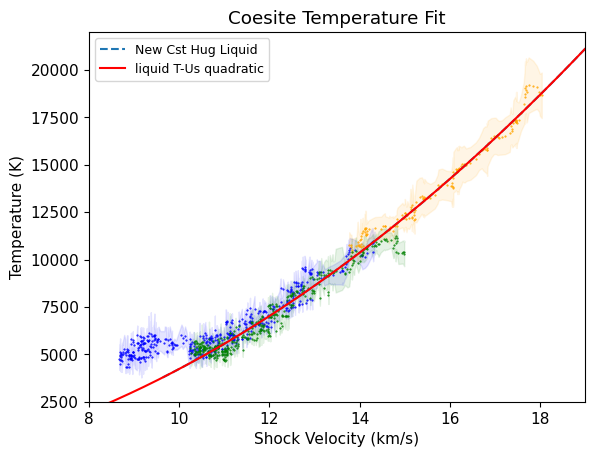

In [6]:

ind39 = np.where(C43939.P > 200)
ind41 = np.where(C43941.P > 200)
ind43 = np.where(C43943.P > 200)

ind39 = np.where(C43939.us > cst_wiggle_us2)
ind41 = np.where(C43941.us > cst_wiggle_us2)
ind43 = np.where(C43943.us > cst_wiggle_us2)

fituscst1 = [C43939.us[ind39],C43941.us[ind41],C43943.us[ind43]]
fituscst = np.concatenate([np.atleast_1d(x) for x in fituscst1])

fittcst1 = [C43939.T[ind39],C43941.T[ind41],C43943.T[ind43]]
fittcst = np.concatenate([np.atleast_1d(x) for x in fittcst1])
fitterrcst1 = [C43939.T_std[ind39],C43941.T_std[ind41],C43943.T_std[ind43]]
fitterrcst = np.concatenate([np.atleast_1d(x) for x in fitterrcst1])


plt.plot(C43939.us,C43939.T,'.',color='b',markersize=1)
plt.fill_between(C43939.us,C43939.T-C43939.T_std,C43939.T+C43939.T_std, color='blue', alpha = 0.1)
plt.plot(C43941.us,C43941.T,'.',color='orange',markersize=1)
plt.fill_between(C43941.us,C43941.T-C43941.T_std,C43941.T+C43941.T_std, color='orange', alpha = 0.1)
plt.plot(C43943.us,C43943.T,'.',color='green',markersize=1)
plt.fill_between(C43943.us,C43943.T-C43943.T_std,C43943.T+C43943.T_std, color='green', alpha = 0.1)

plt.plot(cst_hug_liq.us,cst_hug_liq.T,'--',label='New Cst Hug Liquid')


r1 = np.full(len(fituscst), shockdat_list[F24cst['id']].refidlist[1], dtype=int)
reflist=[]
for i in np.unique(r1):
    reflist.append(str(i)+': '+ref_list[i].reference[0])
if 1:
    # use new fitting system
    print('HPEOS T-Us FIT LIQUID REGION')
    # initialize the HPeos_Fit class
    cst_fitTus_liq = hp.HPeos_Fit()
    cst_fitTus_liq.matid = 149
    cst_fitTus_liq.material = 'Coesite'
    cst_fitTus_liq.formula = 'SiO2'
    cst_fitTus_liq.rho_ref = 2.92
    cst_fitTus_liq.rho_ref_units = 'g/cm³'
    cst_fitTus_liq.x = fituscst
    cst_fitTus_liq.f = fittcst
    cst_fitTus_liq.x_std = fituscst*.01 # assumed
    cst_fitTus_liq.f_std = fitterrcst
    cst_fitTus_liq.refid = r1
    cst_fitTus_liq.reflist = reflist
    cst_fitTus_liq.x_var = 'us'
    cst_fitTus_liq.f_var = 'T'
    cst_fitTus_liq.x_units = 'km/s'
    cst_fitTus_liq.f_units = 'K'
    cst_fitTus_liq.x_desc = 'Shock Velocity'
    cst_fitTus_liq.f_desc = 'Temperature'
    cst_fitTus_liq.phase_fit = 'liquid'
    cst_fitTus_liq.remlist.append('Fit to liquid region on the Hugoniot including supercooled region.')
    DateTime_in_ISOFormat = datetime.datetime.now(zoneinfo.ZoneInfo('UTC')).isoformat('T', 'seconds') #
    cst_fitTus_liq.actions = [['Sarah T. Stewart','create',DateTime_in_ISOFormat,'new fit']]

    cst_fitTus_liq.curvetype = 'quadratic'
    cst_fitTus_liq.outputfitpath = outputfitpath # in load_paths.py
    cst_fitTus_liq.filename = 'cst_fitTus_liq_quadratic'
    cst_fitTus_liq.fit()
    print('FIT EOS a = ',cst_fitTus_liq.a)
    print('FIT EOS cov = ',cst_fitTus_liq.cov)
    cst_fitTus_liq.savejson()
    cst_fitTus_liq.savereadable()
    print('rms = ',cst_fitTus_liq.rms)

    print('cst_fitTus_liq check:')
    cst_fitTus_liq.comparecoefs(cst_fitTus_liq0.a)

    nup = np.arange(.8*cst_fitTus_liq.xrange[0],1.2*cst_fitTus_liq.xrange[1],.04)
    nus = cst_fitTus_liq.calcf(nup)
    #plt.plot(fitus,fittemp,'rX')
    plt.plot(nup,nus,'r-',label='liquid T-Us quadratic')




plt.ylim(4000,20000)
plt.xlabel('Shock Velocity (km/s)')
plt.ylabel('Temperature (K)')
plt.title('Coesite Temperature Fit')
plt.legend(fontsize=lfss)
plt.xlim(8,19)
plt.ylim(2500,22000)
plt.show()

[5.00708396] [91.39509724]
[5.07776448] [102.28031604]
[5.13032202] [111.27237729]
[5.17361327] [119.32368504]
[5.20272417] [125.09503811]


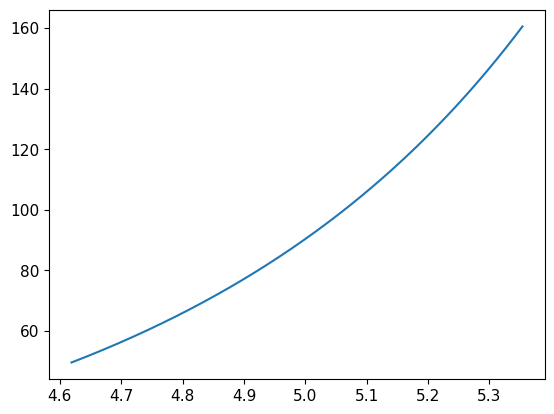

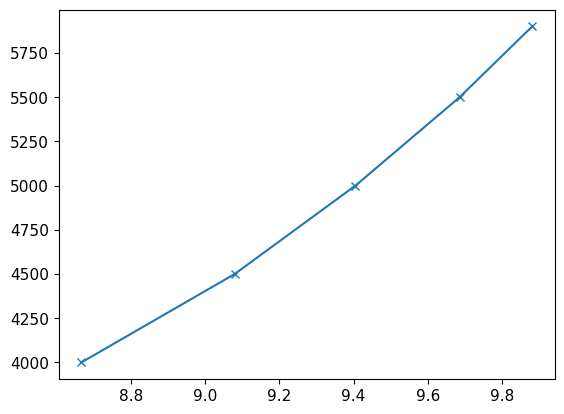

In [7]:

if 1:
    tmpup = cst_hug_cacl2.up
    tmpus = cst_hug_cacl2.us
    tmpp = cst_hug_cacl2.P
    tmprho =  cst_hug_cacl2.rho
    plt.plot(tmprho,tmpp)

    trange = np.asarray([4000,4500,5000,5500,5900])
    rrange = np.zeros(len(trange))
    prange = np.zeros(len(trange))
    x,y = intersection(tmprho,tmpp,stvpvt.rhoarr,stvpvt.p4000)
    print(x,y)
    rrange[0] = x[0]
    prange[0] = y[0]
    x,y = intersection(tmprho,tmpp,stvpvt.rhoarr,stvpvt.p4500)
    print(x,y)
    rrange[1] = x[0]
    prange[1] = y[0]
    x,y = intersection(tmprho,tmpp,stvpvt.rhoarr,stvpvt.p5000)
    print(x,y)
    rrange[2] = x[0]
    prange[2] = y[0]
    x,y = intersection(tmprho,tmpp,stvpvt.rhoarr,stvpvt.p5500)
    print(x,y)
    rrange[3] = x[0]
    prange[3] = y[0]
    x,y = intersection(tmprho,tmpp,stvpvt.rhoarr,stvpvt.p5900)
    print(x,y)
    rrange[4] = x[0]
    prange[4] = y[0]
    usrange = np.interp(prange,tmpp,tmpus)
plt.show()
plt.plot(usrange,trange,'-x')

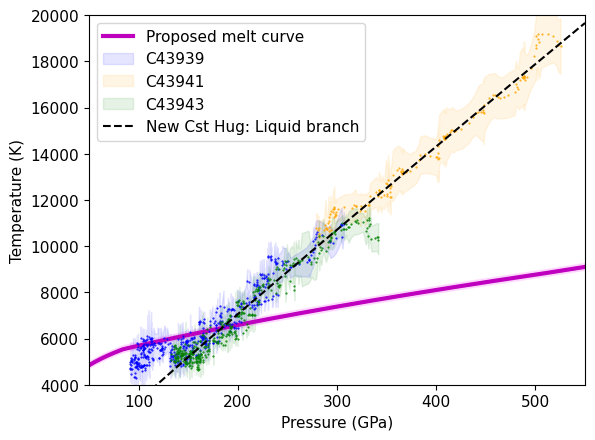

p,t cross liquidus =  [183.61347134] [6449.00922951]
up cross liq =  [5.41098272]
us cross liq =  [11.62105462]
rho cross liq =  [5.46426516]


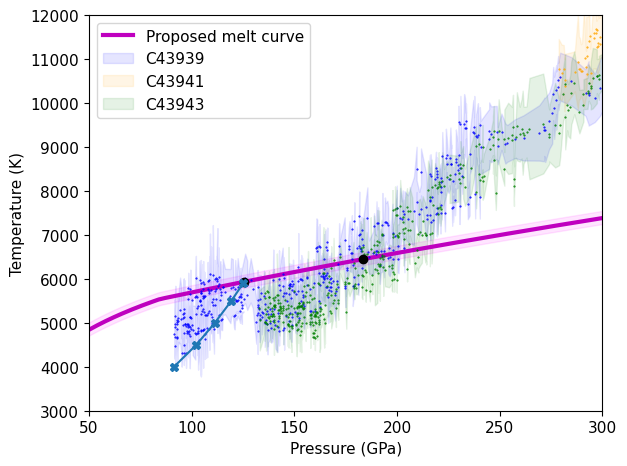

In [8]:
ind = np.where(stsmcsmooth.P <=550)[0]
plt.plot(stsmcsmooth.P[ind],stsmcsmooth.T[ind],'m-',linewidth=3,label='Proposed melt curve')
plt.fill_between(stsmcsmooth.P,stsmcsmooth.T-150,stsmcsmooth.T+150,color='magenta',alpha=0.1)
ind = np.where(stsmcsmooth.P >=550)[0]
plt.plot(stsmcsmooth.P[ind],stsmcsmooth.T[ind],'m:',linewidth=3)



plt.plot(C43939.P,C43939.T,'.',color='b',markersize=1)
plt.fill_between(C43939.P,C43939.T-C43939.T_std,C43939.T+C43939.T_std, color='blue', alpha = 0.1,label='C43939')
plt.plot(C43941.P,C43941.T,'.',color='orange',markersize=1)
plt.fill_between(C43941.P,C43941.T-C43941.T_std,C43941.T+C43941.T_std, color='orange', alpha = 0.1,label='C43941')
plt.plot(C43943.P,C43943.T,'.',color='green',markersize=1)
plt.fill_between(C43943.P,C43943.T-C43943.T_std,C43943.T+C43943.T_std, color='green', alpha = 0.1,label='C43943')

plt.plot(cst_hug_liq.P,cst_hug_liq.T,'k--',label='New Cst Hug: Liquid branch')#$,linewidth=2)

plt.xlim(50,550)
plt.ylim(4000,20000)

plt.xlabel('Pressure (GPa)')
plt.ylabel('Temperature (K)')
plt.legend()
plt.show()

# zoom in

ind = np.where(stsmcsmooth.P <=550)[0]
plt.plot(stsmcsmooth.P[ind],stsmcsmooth.T[ind],'m-',linewidth=3,label='Proposed melt curve')
plt.fill_between(stsmcsmooth.P,stsmcsmooth.T-150,stsmcsmooth.T+150,color='magenta',alpha=0.1)
ind = np.where(stsmcsmooth.P >=550)[0]
plt.plot(stsmcsmooth.P[ind],stsmcsmooth.T[ind],'m:',linewidth=3)

ind = np.where(stsmcsmooth.P <=550)[0]
x,y=intersection(stsmcsmooth.P[ind],stsmcsmooth.T[ind],cst_hug_liq.P,cst_hug_liq.T)
print('p,t cross liquidus = ',x,y)
pcross2=x
print('up cross liq = ',np.interp(x,cst_hug_liq.P,cst_hug_liq.up))
print('us cross liq = ',np.interp(x,cst_hug_liq.P,cst_hug_liq.us))
print('rho cross liq = ',np.interp(x,cst_hug_liq.P,cst_hug_liq.rho))

if 0:
    plt.plot(C43939.P,C43939.T,'.',color='b',markersize=1)
    plt.fill_between(C43939.P,C43939.T-C43939.T_std,C43939.T+C43939.T_std, color='blue', alpha = 0.1)
    plt.plot(C43941.P,C43941.T,'.',color='orange',markersize=1)
    plt.fill_between(C43941.P,C43941.T-C43941.T_std,C43941.T+C43941.T_std, color='orange', alpha = 0.1)
    plt.plot(C43943.P,C43943.T,'.',color='green',markersize=1)
    plt.fill_between(C43943.P,C43943.T-C43943.T_std,C43943.T+C43943.T_std, color='green', alpha = 0.1)


plt.plot(C43939.P,C43939.T,'.',color='b',markersize=1)
plt.fill_between(C43939.P,C43939.T-C43939.T_std,C43939.T+C43939.T_std, color='blue', alpha = 0.1,label='C43939')
plt.plot(C43941.P,C43941.T,'.',color='orange',markersize=1)
plt.fill_between(C43941.P,C43941.T-C43941.T_std,C43941.T+C43941.T_std, color='orange', alpha = 0.1,label='C43941')
plt.plot(C43943.P,C43943.T,'.',color='green',markersize=1)
plt.fill_between(C43943.P,C43943.T-C43943.T_std,C43943.T+C43943.T_std, color='green', alpha = 0.1,label='C43943')


plt.plot([cst_liq_cross.P],[cst_liq_cross.T],'o',color='black')
plt.plot([cst_sol_cross.P],[cst_sol_cross.T],'o',color='black')

plt.plot(prange,trange,'-X')

plt.xlim(50,300)
plt.ylim(3000,12000)
plt.legend()
plt.xlabel('Pressure (GPa)')
plt.ylabel('Temperature (K)')
plt.tight_layout()
plt.savefig(outputfigpath+'Cst-hug-PT.pdf')
plt.show()



[  441.70627827 -6631.87343907 28300.89021108] [[ 1.09970397e+02 -2.03932883e+03  9.43327804e+03]
 [-2.03932883e+03  3.78318083e+04 -1.75062828e+05]
 [ 9.43327804e+03 -1.75062828e+05  8.10394821e+05]]
5928.705041202189
HPEOS T-Us FIT CST-CACL2 MODEL REGION
FIT EOS a =  [28300.89021108 -6631.87343907   441.70627827]
FIT EOS cov =  [[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]]
Saved EOS fit in cst_fitTus_cacl2_quadratic.txt
Saved EOS fit in readable file cst_fitTus_cacl2_quadratic-readable.txt
rms =  2.2771351063525387
cst_fitTus_cacl2 check:
Coefficients are the same.
[28300.89021108 -6631.87343907   441.70627827]
[28300.89021108 -6631.87343907   441.70627827]


/Users/sts/anaconda3/envs/silica/lib/python3.13/site-packages/scipy/odr/_odrpack.py:394: RuntimeWarning: divide by zero encountered in divide
  return 1./np.power(sd, 2)


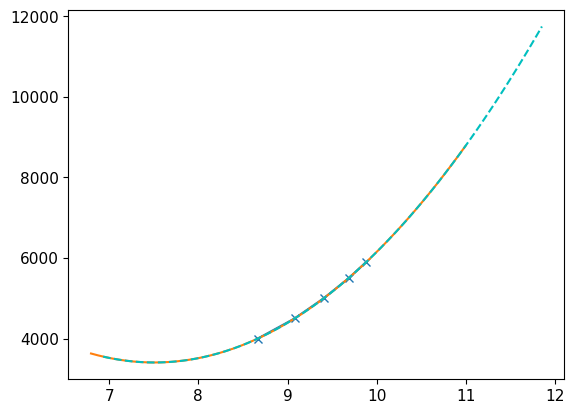

In [9]:
plt.plot(usrange,trange,'x-')
res,cov = np.polyfit(usrange,trange,2,cov=True)
print(res,cov)
tmptemp = res[2]+res[1]*tmpus+res[0]*tmpus*tmpus
plt.plot(tmpus,tmptemp)


tcrosssol = np.interp(cst_sol_cross.us,tmpus,tmptemp)
print(tcrosssol)


r1 = np.full(len(usrange), shockdat_list[A23qtz['id']].refidlist[1], dtype=int)
reflist=[]
for i in np.unique(r1):
    reflist.append(str(i)+': '+ref_list[i].reference[0])
if 1:
    # use new fitting system
    print('HPEOS T-Us FIT CST-CACL2 MODEL REGION')
    # initialize the HPeos_Fit class
    cst_fitTus_cacl2 = hp.HPeos_Fit()
    cst_fitTus_cacl2.matid = 149
    cst_fitTus_cacl2.material = 'Coesite'
    cst_fitTus_cacl2.formula = 'SiO2'
    cst_fitTus_cacl2.rho_ref = 2.92
    cst_fitTus_cacl2.rho_ref_units = 'g/cm³'
    cst_fitTus_cacl2.x = usrange
    cst_fitTus_cacl2.f = trange
    cst_fitTus_cacl2.x_std = np.zeros(len(usrange)) # assumed
    cst_fitTus_cacl2.f_std = np.zeros(len(trange))
    cst_fitTus_cacl2.refid = r1
    cst_fitTus_cacl2.reflist = reflist
    cst_fitTus_cacl2.x_var = 'us'
    cst_fitTus_cacl2.f_var = 'T'
    cst_fitTus_cacl2.x_units = 'km/s'
    cst_fitTus_cacl2.f_units = 'K'
    cst_fitTus_cacl2.x_desc = 'Shock Velocity'
    cst_fitTus_cacl2.f_desc = 'Temperature'
    cst_fitTus_cacl2.phase_fit = 'CaCl2'
    cst_fitTus_cacl2.remlist.append('Fit to model of solid region temperatures on the coesite Hugoniot.')
    DateTime_in_ISOFormat = datetime.datetime.now(zoneinfo.ZoneInfo('UTC')).isoformat('T', 'seconds') #
    cst_fitTus_cacl2.actions = [['Sarah T. Stewart','create',DateTime_in_ISOFormat,'new fit']]

    cst_fitTus_cacl2.curvetype = 'quadratic'
    cst_fitTus_cacl2.outputfitpath = outputfitpath # in load_paths.py
    cst_fitTus_cacl2.filename = 'cst_fitTus_cacl2_quadratic'
    cst_fitTus_cacl2.fit()
    print('FIT EOS a = ',cst_fitTus_cacl2.a)
    print('FIT EOS cov = ',cst_fitTus_cacl2.cov)
    cst_fitTus_cacl2.savejson()
    cst_fitTus_cacl2.savereadable()
    print('rms = ',cst_fitTus_cacl2.rms)

    print('cst_fitTus_cacl2 check:')
    cst_fitTus_cacl2.comparecoefs(cst_fitTus_cacl20.a)

    nup = np.arange(.8*cst_fitTus_cacl2.xrange[0],1.2*cst_fitTus_cacl2.xrange[1],.04)
    nus = cst_fitTus_cacl2.calcf(nup)
    #plt.plot(fitus,fittemp,'rX')
    plt.plot(nup,nus,'c--',label='solid T-Us quadratic')




plt.show()

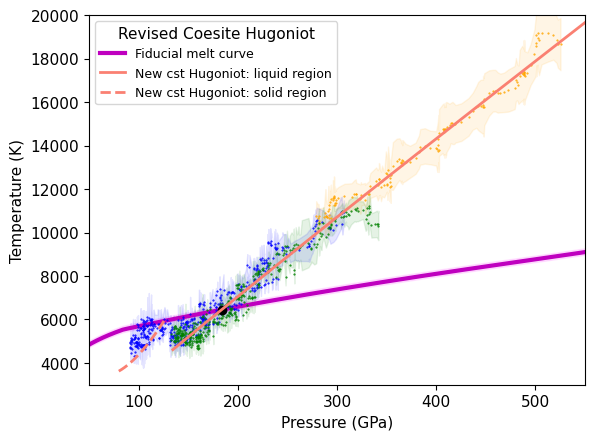

In [10]:
ind = np.where(stsmcsmooth.P <=550)[0]
plt.plot(stsmcsmooth.P[ind],stsmcsmooth.T[ind],'m-',linewidth=3,label='Fiducial melt curve')
plt.fill_between(stsmcsmooth.P,stsmcsmooth.T-150,stsmcsmooth.T+150,color='magenta',alpha=0.1)
ind = np.where(stsmcsmooth.P >=550)[0]
plt.plot(stsmcsmooth.P[ind],stsmcsmooth.T[ind],'m:',linewidth=3)



plt.plot(C43939.P,C43939.T,'.',color='b',markersize=1)
plt.fill_between(C43939.P,C43939.T-C43939.T_std,C43939.T+C43939.T_std, color='blue', alpha = 0.1)
plt.plot(C43941.P,C43941.T,'.',color='orange',markersize=1)
plt.fill_between(C43941.P,C43941.T-C43941.T_std,C43941.T+C43941.T_std, color='orange', alpha = 0.1)
plt.plot(C43943.P,C43943.T,'.',color='green',markersize=1)
plt.fill_between(C43943.P,C43943.T-C43943.T_std,C43943.T+C43943.T_std, color='green', alpha = 0.1)


plt.xlim(50,550)
plt.ylim(3000,20000)
plt.plot(cst_liquidus_P,cst_liquidus_T,'ko')

ind = np.where(cst_hug_liq.P > cst_wiggle_P2)[0]
plt.plot(cst_hug_liq.P[ind],cst_hug_liq.T[ind],'-',color='salmon',linewidth=2,label='New cst Hugoniot: liquid region')
ind = np.where((cst_hug_cacl2.P<cst_sol_cross.P) & (cst_hug_cacl2.P>80))[0]
plt.plot(cst_hug_cacl2.P[ind],cst_hug_cacl2.T[ind],'--',color='salmon',linewidth=2,label='New cst Hugoniot: solid region')
plt.xlabel('Pressure (GPa)')
plt.ylabel('Temperature (K)')
plt.legend(fontsize=lfss,title='Revised Coesite Hugoniot')
plt.show()


## Check consistency between EOS and Hugoniot Fits

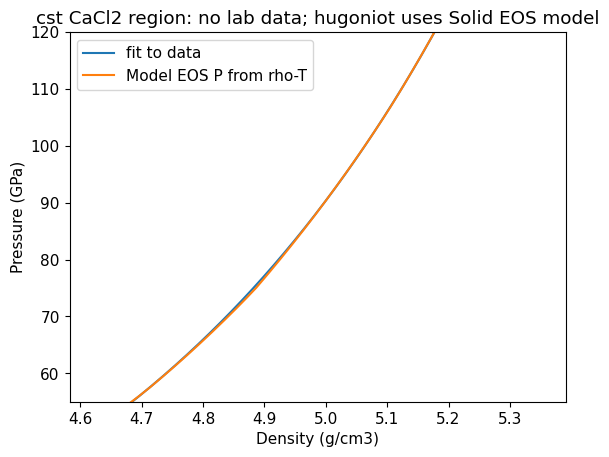

In [11]:
pmodel=[]
for iii in range(len(cst_hug_cacl2.T)):
    stvpvt.isotherm_stv(cst_hug_cacl2.T[iii])
    pmodel.append(np.interp(cst_hug_cacl2.rho[iii],stvpvt.rhoarr,stvpvt.isotherm_p))


plt.plot(cst_hug_cacl2.rho,cst_hug_cacl2.P,label='fit to data')
plt.plot(cst_hug_cacl2.rho,pmodel,label='Model EOS P from rho-T')
plt.title('cst CaCl2 region: no lab data; hugoniot uses Solid EOS model')
plt.ylim(55,120)
plt.legend()
plt.xlabel('Density (g/cm3)')
plt.ylabel('Pressure (GPa)')
#plt.savefig(outputfigpath+'cst-cacl2-test.pdf')
plt.show()
